### First data and libraries should be imported

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

data = pd.read_csv('dermatology_database_1.csv')

### See what is in the dataset

In [2]:
data.info()
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                               Non-Null Count  Dtype 
---  ------                               --------------  ----- 
 0   erythema                             366 non-null    int64 
 1   scaling                              366 non-null    int64 
 2   definite_borders                     366 non-null    int64 
 3   itching                              366 non-null    int64 
 4   koebner_phenomenon                   366 non-null    int64 
 5   polygonal_papules                    366 non-null    int64 
 6   follicular_papules                   366 non-null    int64 
 7   oral_mucosal_involvement             366 non-null    int64 
 8   knee_and_elbow_involvement           366 non-null    int64 
 9   scalp_involvement                    366 non-null    int64 
 10  family_history                       366 non-null    int64 
 11  melanin_incontinence                 366 non-

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,focal_hypergranulosis,disappearance_granular_layer,vacuolisation_damage_basal_layer,spongiosis,saw_tooth_appearance_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_mononuclear_infiltrate,band_like_infiltrate,class
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,...,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,2.068306,1.795082,1.549180,1.366120,0.633880,0.448087,0.166667,0.377049,0.614754,0.519126,...,0.393443,0.464481,0.456284,0.953552,0.453552,0.103825,0.114754,1.866120,0.554645,2.803279
std,0.664753,0.701527,0.907525,1.138299,0.908016,0.957327,0.570588,0.834147,0.982979,0.905639,...,0.849406,0.864899,0.954873,1.130172,0.954744,0.450433,0.488723,0.726108,1.105908,1.597803
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
50%,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,3.000000
75%,2.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.000000,4.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,6.000000


In [3]:
data.head(10)

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_granular_layer,vacuolisation_damage_basal_layer,spongiosis,saw_tooth_appearance_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_mononuclear_infiltrate,band_like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3
5,2,3,2,0,0,0,0,0,0,0,...,0,0,2,0,0,0,1,0,41,2
6,2,1,0,2,0,0,0,0,0,0,...,0,0,0,0,0,0,2,0,18,5
7,2,2,3,3,3,3,0,2,0,0,...,2,2,3,2,0,0,3,3,57,3
8,2,2,1,0,2,0,0,0,0,0,...,0,0,2,0,0,0,2,0,22,4
9,2,2,1,0,1,0,0,0,0,0,...,0,0,2,0,0,0,2,0,30,4


- There are 366 subjects 
- There are 6 classes
- There are 34 features: 
- 32 features can take the values of 0,1,2,3
- age can take any integer value
- family_history can take the values 0,1

- age feature has 8 missing values that needs to be imputed

### Explore the data visually

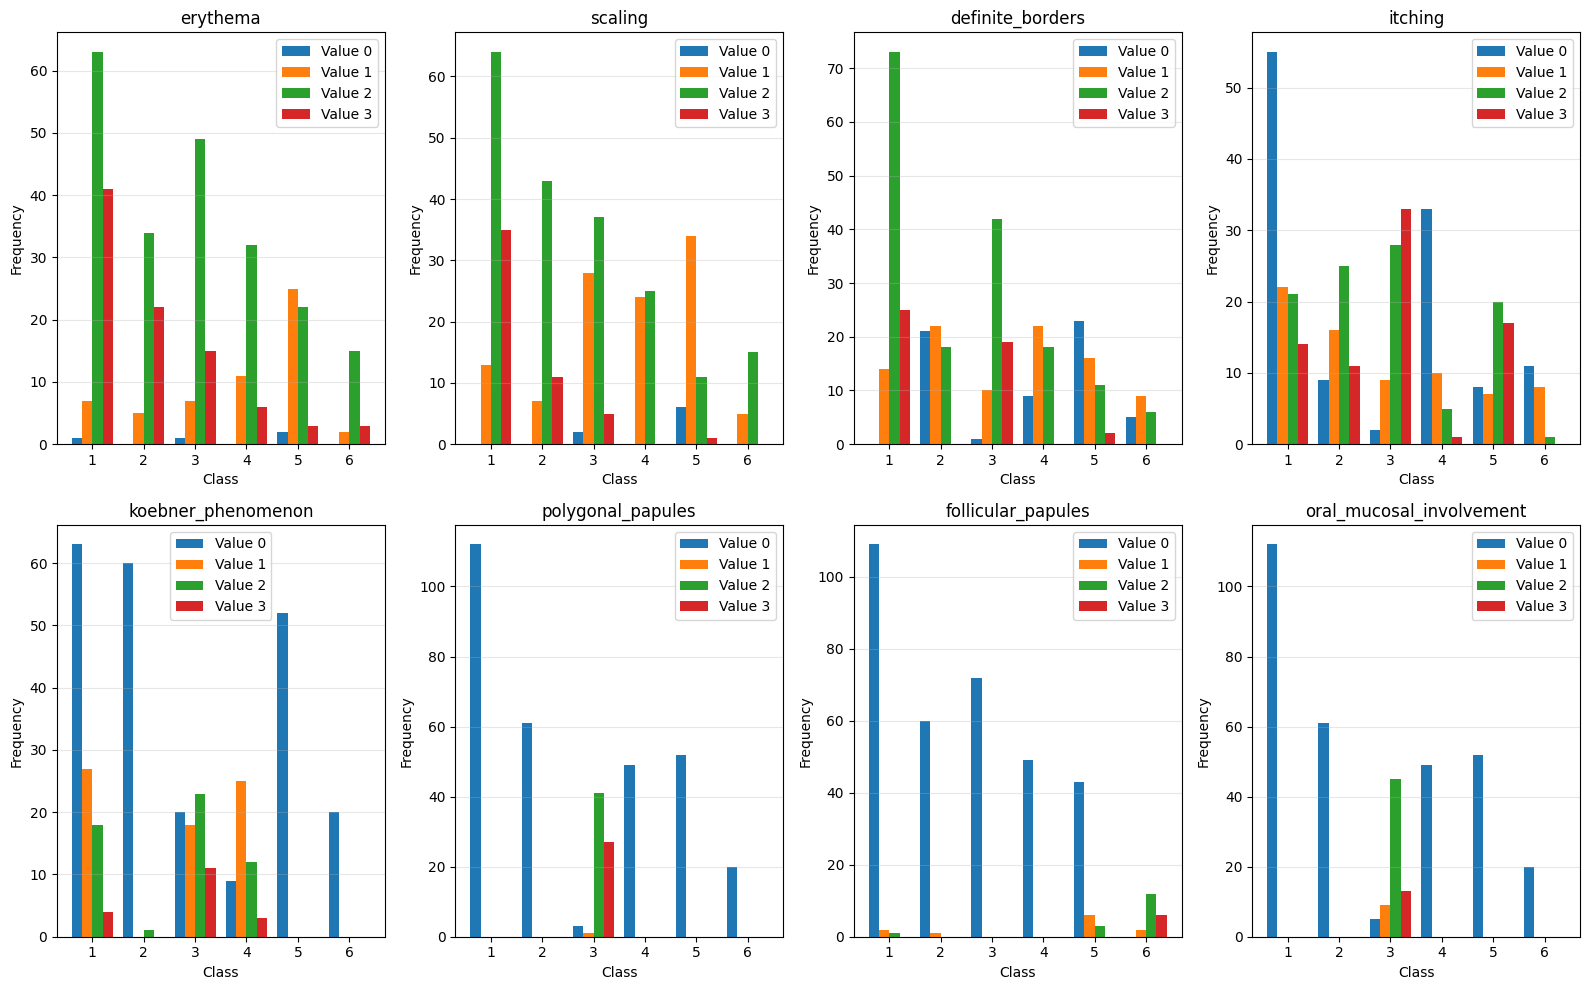

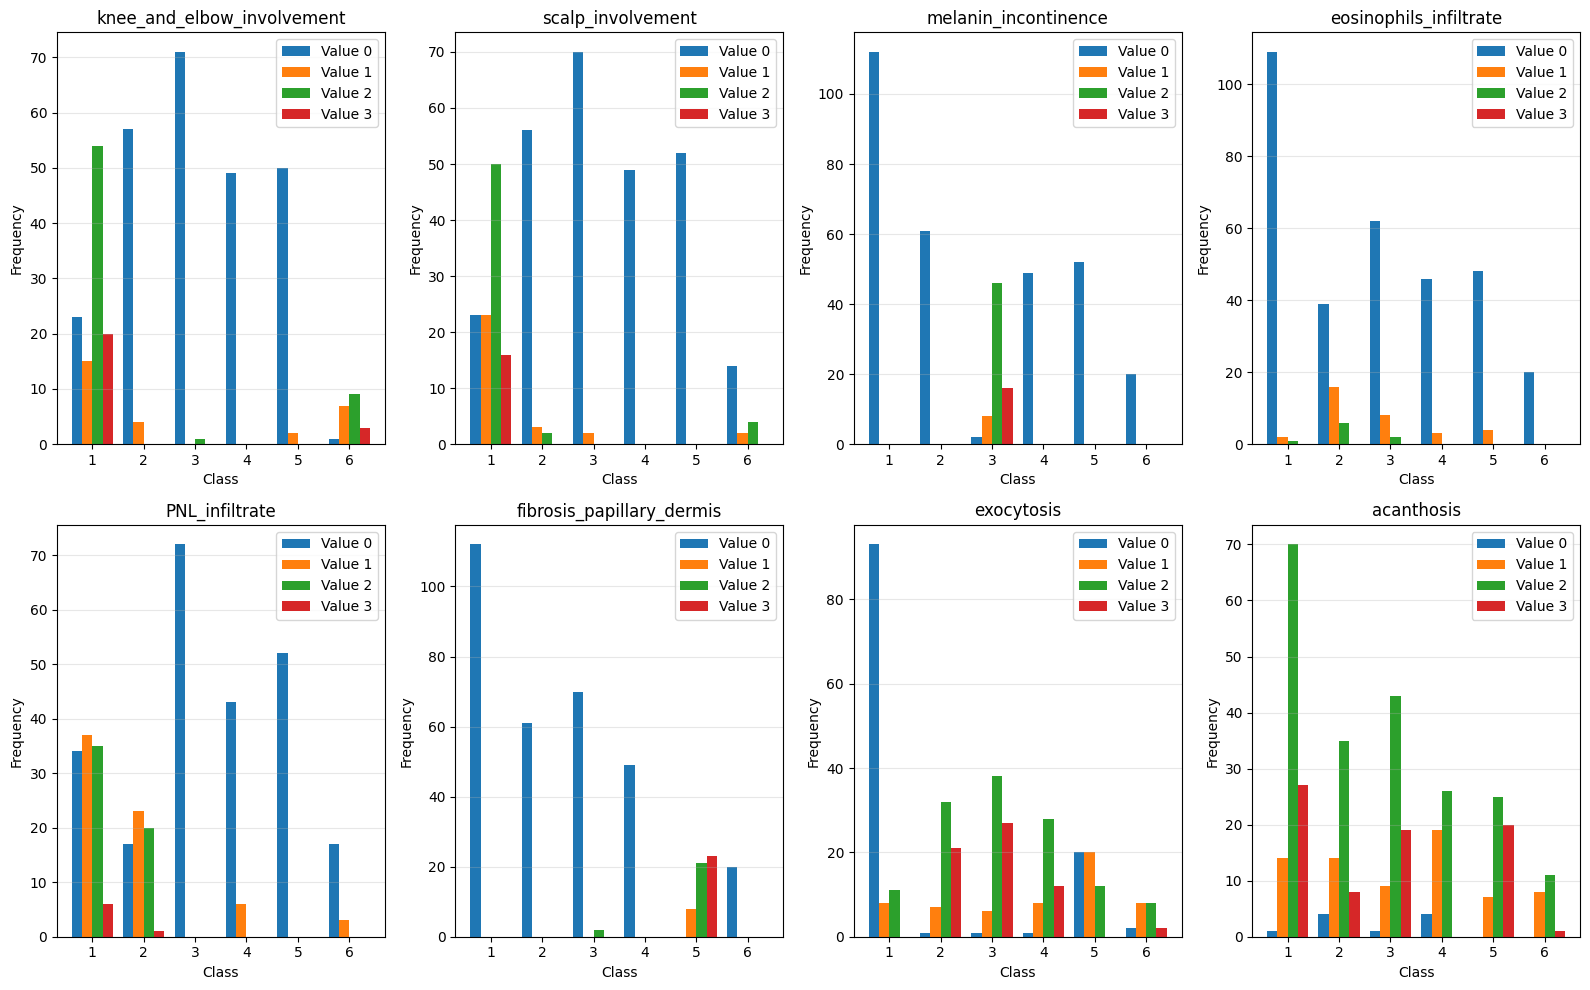

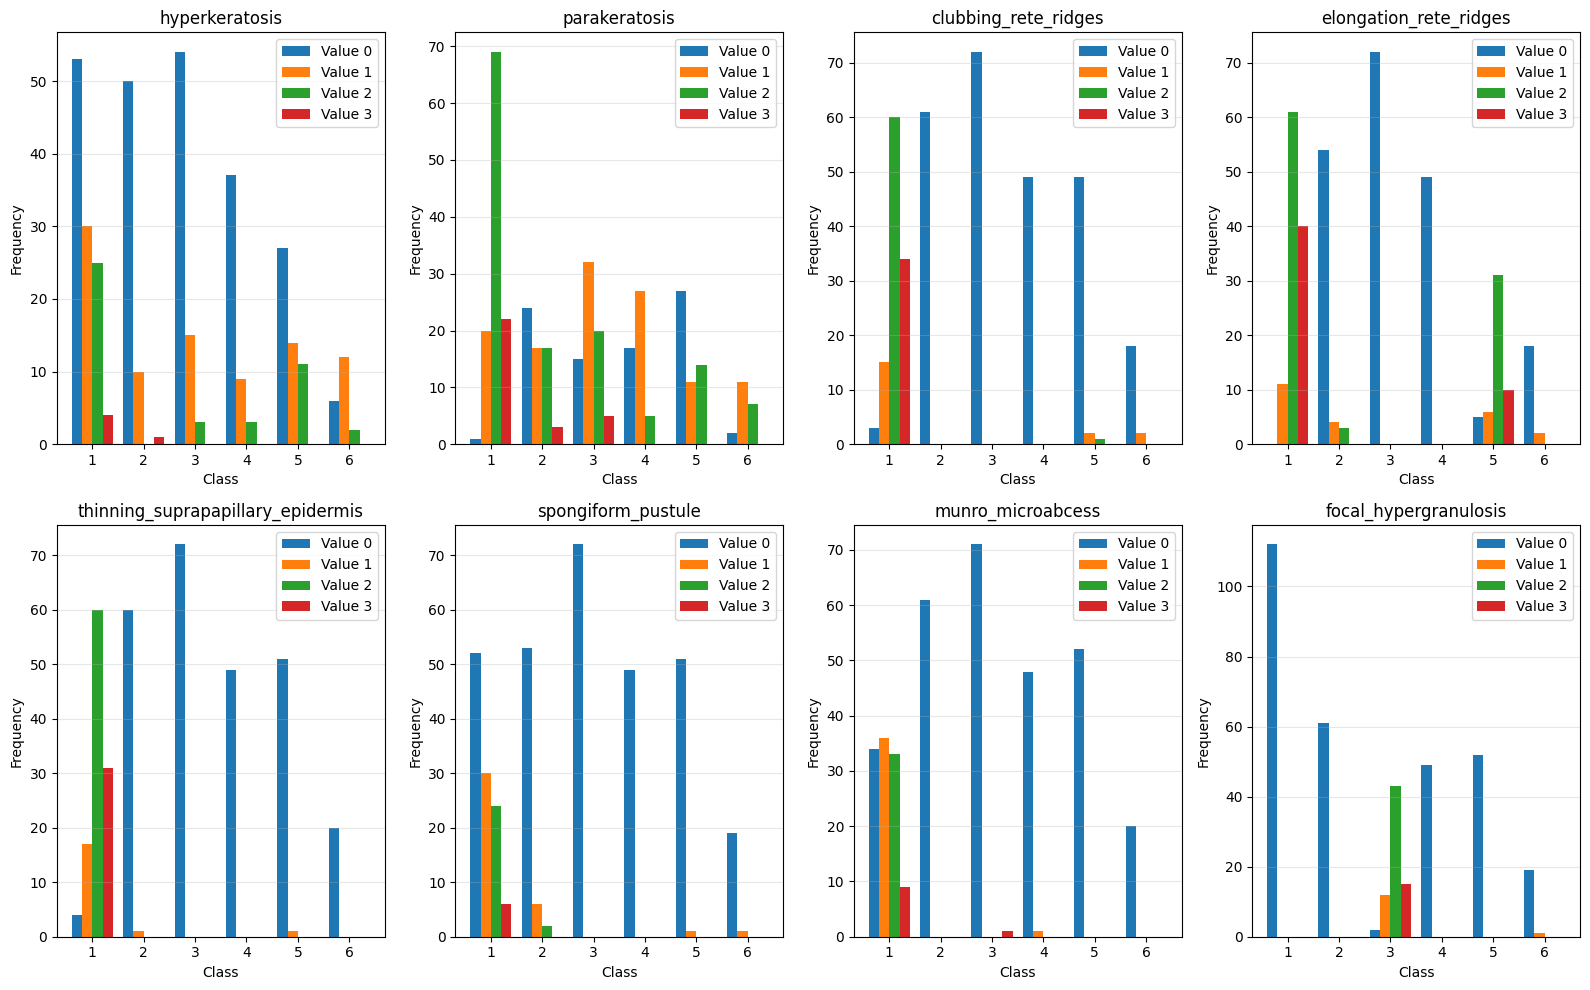

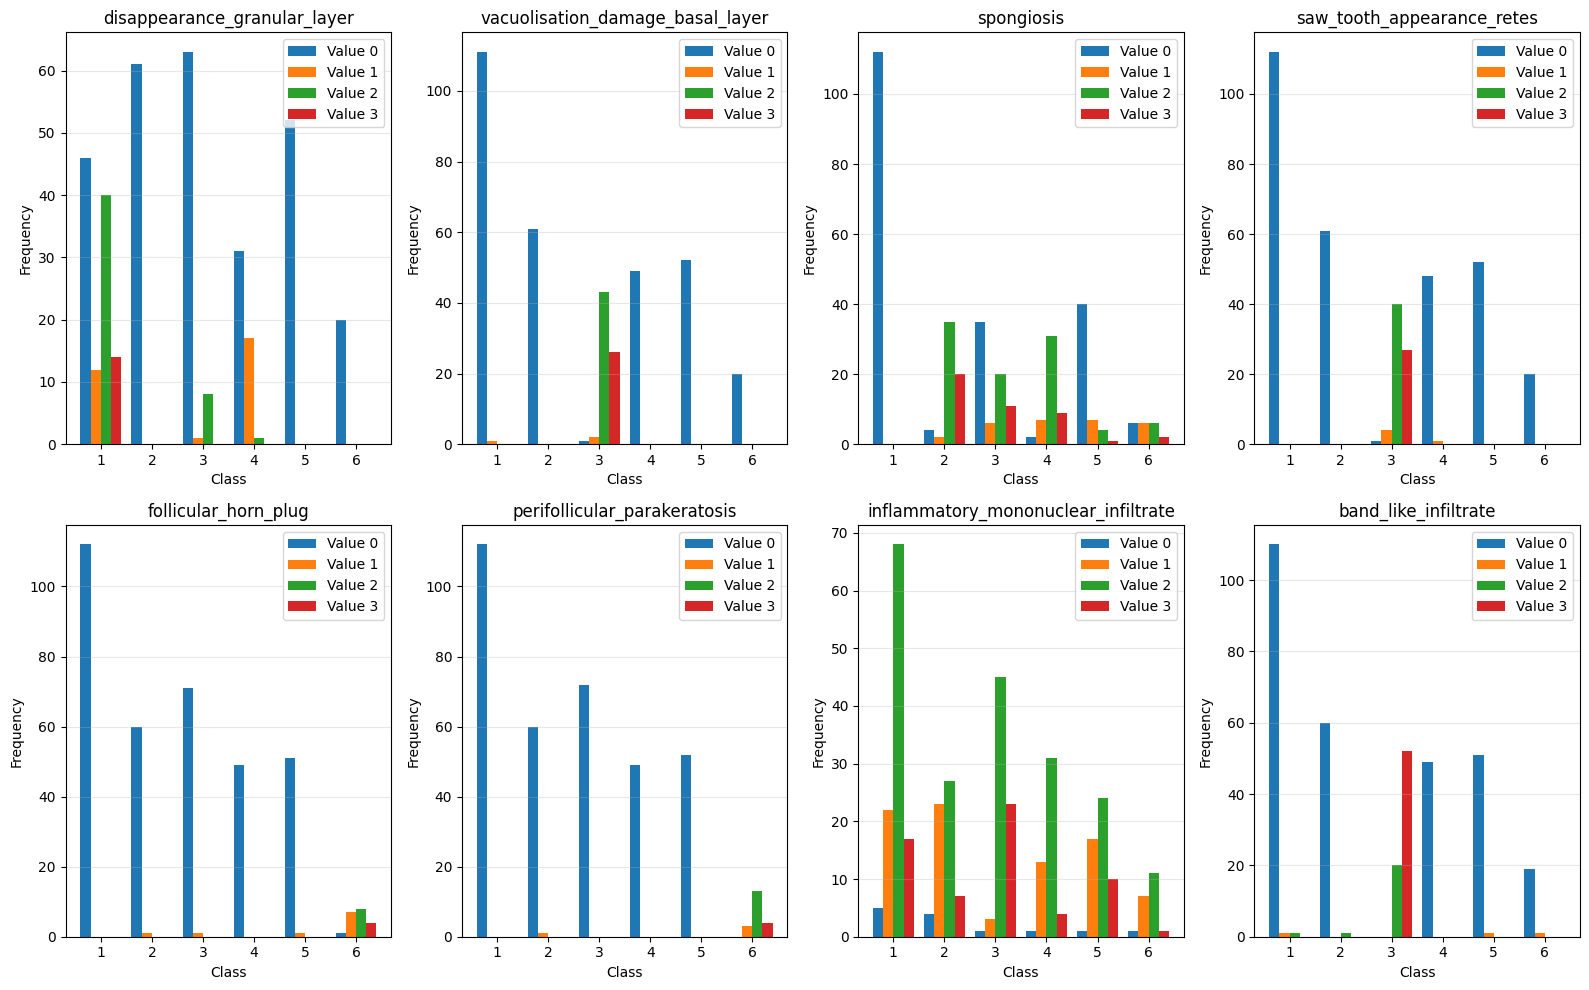

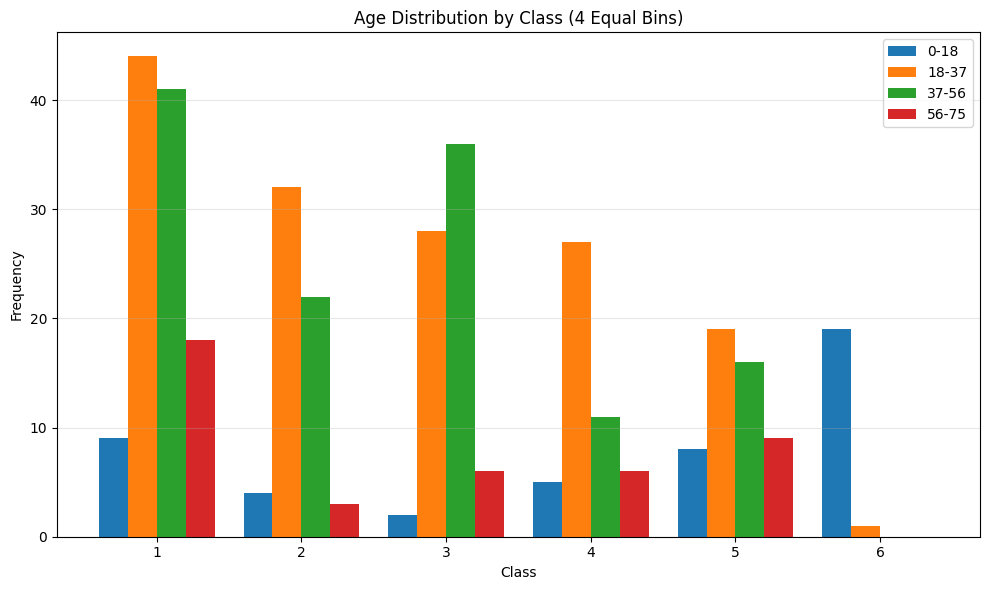

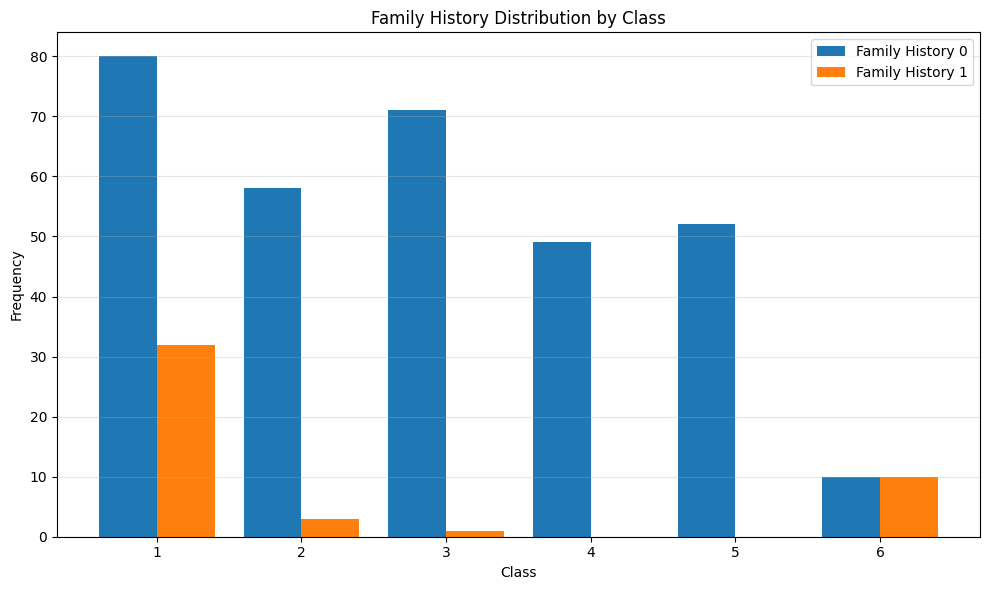

In [4]:
# Convert age to numeric (in case it's read as string)
data['age'] = pd.to_numeric(data['age'], errors='coerce')

# Get all columns except 'class'
features = [col for col in data.columns if col != 'class']
classes = sorted(data['class'].unique())
 
# Separate features into different types
regular_features = [f for f in features if f not in ['age', 'family_history']]
age_col = 'age'
family_history_col = 'family_history'

# Create visualizations for regular features (0-3 values)
n_regular = len(regular_features)
features_per_figure = 8
n_cols = 4
n_rows = 2  # 8 features = 2 rows x 4 cols

# Process features in batches of 8
for batch_idx in range(0, n_regular, features_per_figure):
    batch_features = regular_features[batch_idx:batch_idx + features_per_figure]
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 10))
    axes = axes.flatten()
    
    for plot_idx, feature in enumerate(batch_features):
        ax = axes[plot_idx]
        
        # Prepare data for grouped bar chart
        x_pos = np.arange(len(classes))
        bar_width = 0.2
        
        for value in [0, 1, 2, 3]:
            frequencies = []
            for cls in classes:
                freq = ((data[(data['class'] == cls) & (data[feature] == value)].shape[0]))
                frequencies.append(freq)
            ax.bar(x_pos + value * bar_width, frequencies, bar_width, label=f'Value {value}')
        
        ax.set_xlabel('Class')
        ax.set_ylabel('Frequency')
        ax.set_title(feature)
        ax.set_xticks(x_pos + 1.5 * bar_width)
        ax.set_xticklabels(classes)
        ax.legend()
        ax.grid(axis='y', alpha=0.3)
    
    # Hide unused subplots
    for idx in range(len(batch_features), len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    batch_num = (batch_idx // features_per_figure) + 1
    plt.show()
# Visualization for Age (4 equal bins)
fig, ax = plt.subplots(figsize=(10, 6))

# Split age into 4 equal bins
age_min, age_max = data[age_col].min(), data[age_col].max()
age_bins = np.linspace(age_min, age_max, 5)  # 5 edges for 4 bins
bin_labels = [f'{int(age_bins[i])}-{int(age_bins[i+1])}' for i in range(len(age_bins)-1)]

# Digitize ages into bins
age_binned = np.digitize(data[age_col], age_bins) - 1
age_binned = np.clip(age_binned, 0, 3)  # Ensure within 0-3 range

x_pos = np.arange(len(classes))
bar_width = 0.2

for bin_idx in range(4):
    frequencies = []
    for cls in classes:
        freq = ((data[(data['class'] == cls) & (age_binned == bin_idx)].shape[0]))
        frequencies.append(freq)
    ax.bar(x_pos + bin_idx * bar_width, frequencies, bar_width, label=bin_labels[bin_idx])

ax.set_xlabel('Class')
ax.set_ylabel('Frequency')
ax.set_title('Age Distribution by Class (4 Equal Bins)')
ax.set_xticks(x_pos + 1.5 * bar_width)
ax.set_xticklabels(classes)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Visualization for Family History (2 values: 0 and 1)
fig, ax = plt.subplots(figsize=(10, 6))

x_pos = np.arange(len(classes))
bar_width = 0.4

for value in [0, 1]:
    frequencies = []
    for cls in classes:
        freq = ((data[(data['class'] == cls) & (data[family_history_col] == value)].shape[0]))
        frequencies.append(freq)
    ax.bar(x_pos + value * bar_width, frequencies, bar_width, label=f'Family History {value}')

ax.set_xlabel('Class')
ax.set_ylabel('Frequency')
ax.set_title('Family History Distribution by Class')
ax.set_xticks(x_pos + bar_width / 2)
ax.set_xticklabels(classes)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()



Results of exploratation using bar graph: Some clear patterns are recognized, a tree based classification algorithm can be used

### Split data as training and test sets

In [5]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# Prepare features and target
X = data.drop(columns=["class"]).copy()
y = data["class"].copy()


# Hold out a final test set. Do not use this during tuning.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

### Preprocces the age data

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import KBinsDiscretizer


age_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("binner", KBinsDiscretizer(n_bins=4, encode="ordinal", strategy="uniform")),
])

age_features = ["age"]
other_features = [col for col in X.columns if col != "age"]

preprocess = ColumnTransformer(
    transformers=[
        ("age", age_pipeline, age_features),
        ("other_features", "passthrough", other_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False
)


### Define Tree-based algorithms

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Decision Tree": Pipeline(steps=[
        ("preprocess", preprocess),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocess", preprocess),
        ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    "Gradient Boosting": Pipeline(steps=[
        ("preprocess", preprocess),
        ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
    ])
}

### Define Scoring Metrics

In [8]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    make_scorer
)


scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": make_scorer(f1_score, average="macro"),
    "f1_weighted": make_scorer(f1_score, average="weighted"),
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
    "roc_auc_ovr_weighted": "roc_auc_ovr_weighted",
}

### Parameter space for tuning

In [10]:
import scipy
from scipy.stats import randint, uniform, loguniform

param_distributions = {
    "Decision Tree": {
        "model__criterion": ["gini", "entropy", "log_loss"],
        "model__max_depth": [None] + list(range(2, 21)),
        "model__min_samples_split": randint(2, 21),
        "model__min_samples_leaf": randint(1, 11),
        "model__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "model__n_estimators": randint(100, 801),
        "model__max_depth": [None] + list(range(2, 31)),
        "model__min_samples_split": randint(2, 21),
        "model__min_samples_leaf": randint(1, 11),
        "model__max_features": ["sqrt", "log2", None],
        "model__class_weight": [None, "balanced"],
        "model__bootstrap": [True, False],
    },
    "Gradient Boosting": {
        "model__n_estimators": randint(50, 401),
        "model__learning_rate": loguniform(0.01, 0.30),
        "model__max_depth": randint(1, 6),
        "model__min_samples_split": randint(2, 21),
        "model__min_samples_leaf": randint(1, 11),
        "model__subsample": uniform(0.70, 0.30),  # samples values from 0.70 to 1.00
    },
}


### Cross Validation

In [11]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

random_searches = {}
cv_summary_rows = []

N_ITER = 60

for model_name, estimator in models.items():
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_distributions[model_name],
        n_iter=N_ITER,
        scoring=scoring,
        refit="f1_macro",       # primary model-selection metric
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        return_train_score=True,
        error_score="raise"
    )

    search.fit(X_train, y_train)
    random_searches[model_name] = search

    best_idx = search.best_index_
    row = {
        "model": model_name,
        "best_refit_score_f1_macro": search.best_score_,
        "best_params": search.best_params_,
    }

    for metric in scoring.keys():
        row[f"cv_mean_{metric}"] = search.cv_results_[f"mean_test_{metric}"][best_idx]
        row[f"cv_std_{metric}"] = search.cv_results_[f"std_test_{metric}"][best_idx]

    cv_summary_rows.append(row)

### CV Results and Best Model Selection

In [12]:
cv_summary = (
    pd.DataFrame(cv_summary_rows)
    .sort_values("cv_mean_f1_macro", ascending=False)
    .reset_index(drop=True)
)

display(cv_summary[[
    "model",
    "cv_mean_f1_macro",
    "cv_std_f1_macro",
    "cv_mean_balanced_accuracy",
    "cv_std_balanced_accuracy",
    "cv_mean_accuracy",
    "cv_std_accuracy",
    "cv_mean_roc_auc_ovr_weighted",
    "cv_std_roc_auc_ovr_weighted",
    "best_params"
]])

best_model_name = cv_summary.loc[0, "model"]
best_search = random_searches[best_model_name]
best_model = best_search.best_estimator_

print(f"\nBest model selected by cross-validated macro F1: {best_model_name}")
print("Best parameters:")
print(best_search.best_params_)

,model,cv_mean_f1_macro,cv_std_f1_macro,cv_mean_balanced_accuracy,cv_std_balanced_accuracy,cv_mean_accuracy,cv_std_accuracy,cv_mean_roc_auc_ovr_weighted,cv_std_roc_auc_ovr_weighted,best_params
0,Random Forest,0.984650,0.007678,0.983796,0.008151,0.986324,0.006839,0.999441,0.000791,"{'model__bootstrap': False, 'model__class_weig..."
1,Gradient Boosting,0.970592,0.028614,0.966204,0.035729,0.975979,0.020632,0.998805,0.001502,"{'model__learning_rate': 0.02171140223187999, ..."
2,Decision Tree,0.953460,0.015988,0.951162,0.020162,0.958913,0.017300,0.980981,0.013881,"{'model__class_weight': 'balanced', 'model__cr..."



Best model selected by cross-validated macro F1: Random Forest
Best parameters:
{'model__bootstrap': False, 'model__class_weight': 'balanced', 'model__max_depth': 15, 'model__max_features': 'log2', 'model__min_samples_leaf': 7, 'model__min_samples_split': 3, 'model__n_estimators': 738}


### Testing

,test_score
roc_auc_ovr_weighted,0.997630
accuracy,0.959459
f1_weighted,0.959329
recall_macro,0.955556
balanced_accuracy,0.955556
f1_macro,0.943076
precision_macro,0.934848


Classification report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.91      0.83      0.87        12
           3       1.00      1.00      1.00        15
           4       0.90      0.90      0.90        10
           5       1.00      1.00      1.00        10
           6       0.80      1.00      0.89         4

    accuracy                           0.96        74
   macro avg       0.93      0.96      0.94        74
weighted avg       0.96      0.96      0.96        74



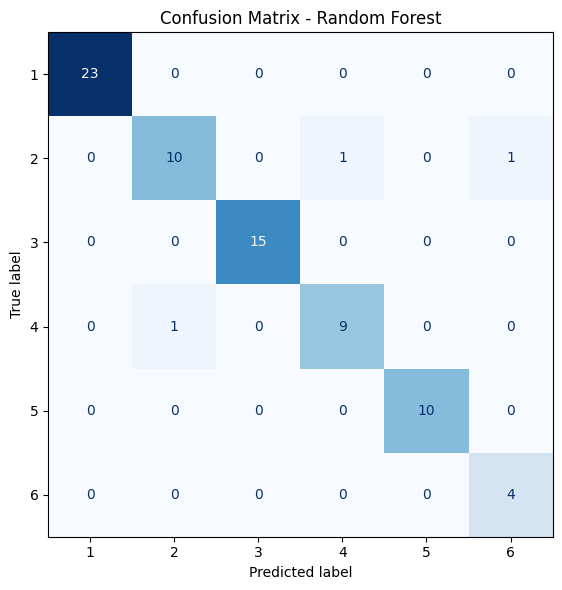

In [13]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Predict on the untouched test set
y_pred = best_model.predict(X_test)

# roc-auc need class probabilities
y_proba = best_model.predict_proba(X_test)

test_results = {
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "f1_macro": f1_score(y_test, y_pred, average="macro"),
    "f1_weighted": f1_score(y_test, y_pred, average="weighted"),
    "precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "roc_auc_ovr_weighted": roc_auc_score(
        y_test,
        y_proba,
        multi_class="ovr",
        average="weighted",
        labels=best_model.classes_
    ),
}

test_results_df = (
    pd.DataFrame.from_dict(test_results, orient="index", columns=["test_score"])
    .sort_values("test_score", ascending=False)
)

display(test_results_df)

print("Classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=best_model.classes_)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()